**Inisialisasi Data & Data Cleaning**


In [7]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

csv_data = """id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
TRX0244483,2024-09-04,G11,K029,RMT1407,3,7500,0,SELESAI
TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI
TRX0240658,2025-07-18,G01,K008,RMT1408,12,45500,10,SELESAI
TRX0244581,2025-09-24,G10,K021,MIN1004,1,18000,0,SELESAI
TRX0244786,2025-11-02,G01,K024,SGR1207,1,11500,20,SELESAI
TRX0241902,2025-01-15,G02,K003,PRW1306,5,25000,5,SELESAI
TRX0243110,2025-03-10,G03,K005,MIN1009,3,10000,0,SELESAI
TRX0242221,2025-05-12,G04,K002,SGR1205,2,21000,0,SELESAI
TRX0243889,2025-08-20,G06,K012,MKN1100,4,8000,10,SELESAI
TRX0241554,2025-10-05,G08,K019,PRW1309,2,30000,0,SELESAI
TRX0242890,2025-12-14,G02,K007,SGR1202,3,15000,5,SELESAI
TRX0241333,2025-02-18,G01,K004,SGR1204,1,12000,0,BATAL
TRX0244102,2025-04-22,G07,K014,RMT1404,2,22000,0,RETUR"""

df = pd.read_csv(io.StringIO(csv_data))
df['harga_satuan'] = (
    df['harga_satuan'].astype(str).str.replace(',', '.').astype(float)
)
df['tanggal'] = pd.to_datetime(df['tanggal'], format='mixed', errors='coerce')
df['total_penjualan'] = (
    df['jumlah'] * df['harga_satuan'] * (1 - df['diskon_persen'] / 100)
)
df_2025 = df[df['tanggal'].dt.year == 2025].copy()

**Bagian 1 — Penjualan per Bulan Tahun 2025**

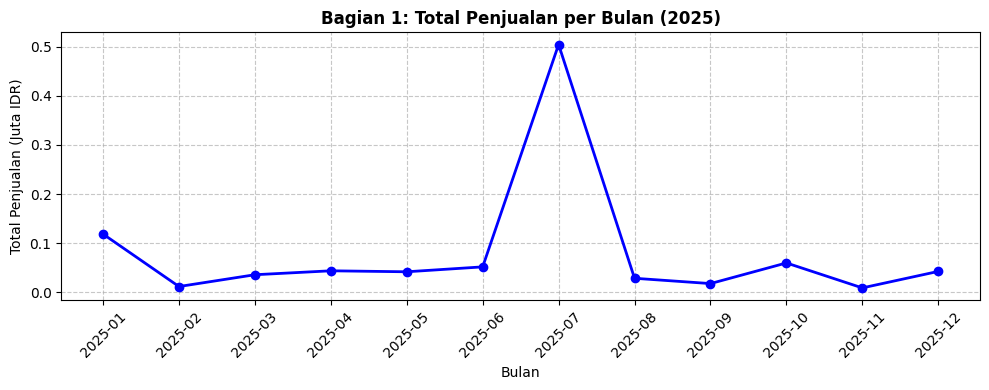

In [8]:
df_2025['bulan_str'] = df_2025['tanggal'].dt.strftime('%Y-%m')
penjualan_per_bulan = df_2025.groupby('bulan_str')['total_penjualan'].sum()

plt.figure(figsize=(10, 4))
plt.plot(
    penjualan_per_bulan.index,
    penjualan_per_bulan.values / 1e6,
    marker='o',
    color='b',
    linewidth=2,
)
plt.title('Bagian 1: Total Penjualan per Bulan (2025)', fontweight='bold')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Juta IDR)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Bagian 2 — 10 Produk Terlaris Tahun 2025**

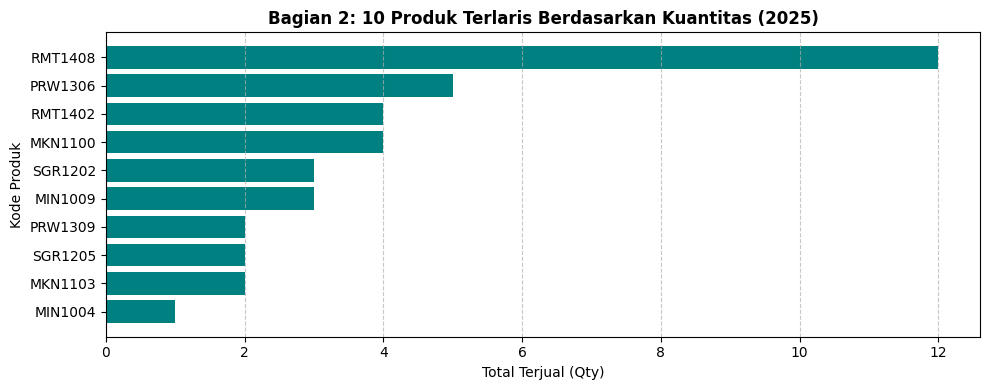

In [9]:
top_10_produk = (
    df_2025[df_2025['status'] == 'SELESAI']
    .groupby('kode_produk')['jumlah']
    .sum()
    .nlargest(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 4))
plt.barh(top_10_produk.index, top_10_produk.values, color='teal')
plt.title(
    'Bagian 2: 10 Produk Terlaris Berdasarkan Kuantitas (2025)',
    fontweight='bold',
)
plt.xlabel('Total Terjual (Qty)')
plt.ylabel('Kode Produk')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Bagian 3 — Proporsi Transaksi Berhasil vs Gagal/Cancel**

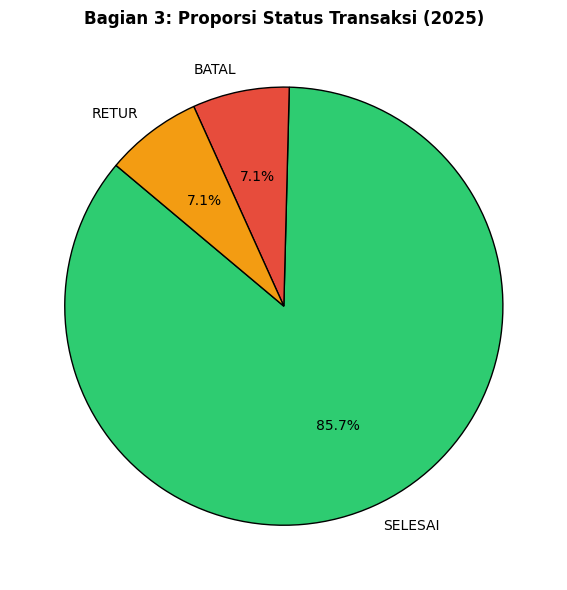

In [10]:
status_counts = df_2025['status'].value_counts()

plt.figure(figsize=(6, 6))
colors = ['#2ecc71', '#e74c3c', '#f39c12']
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors[: len(status_counts)],
    wedgeprops={'edgecolor': 'black'},
)
plt.title('Bagian 3: Proporsi Status Transaksi (2025)', fontweight='bold')
plt.tight_layout()
plt.show()

**Bagian 4 — Hubungan Jumlah Beli dengan Diskon**

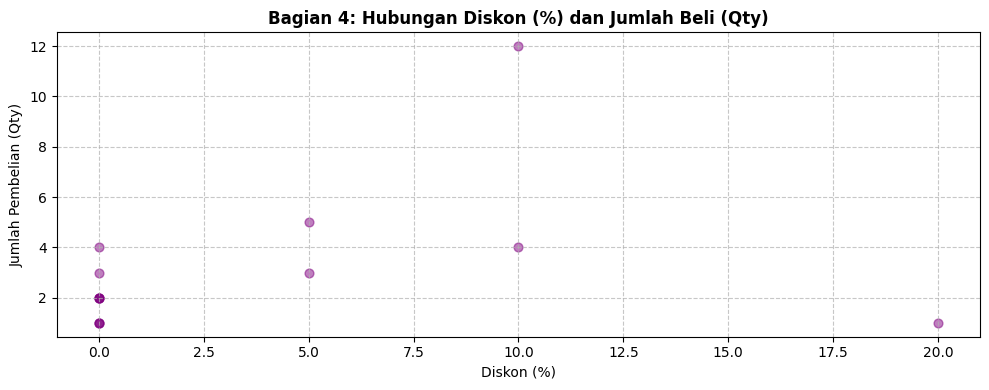

In [11]:
df_valid = df_2025[(df_2025['jumlah'] > 0) & (df_2025['jumlah'] < 100)]

plt.figure(figsize=(10, 4))
plt.scatter(
    df_valid['diskon_persen'],
    df_valid['jumlah'],
    alpha=0.5,
    color='purple',
    s=40,
)
plt.title('Bagian 4: Hubungan Diskon (%) dan Jumlah Beli (Qty)', fontweight='bold')
plt.xlabel('Diskon (%)')
plt.ylabel('Jumlah Pembelian (Qty)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()